In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

In [ ]:
df = pd.read_csv("final_dav_dataset.csv")

In [ ]:
import plotly.express as px
import plotly.graph_objects as go
import plotly.io as pio

In [ ]:
df.head()

,Event Type,Attendees,Expenses,Success
0,Sports,853,35012,0
1,Cultural,670,159726,1
2,Cultural,1113,176284,1
3,Sports,1074,218188,1
4,Seminars,1013,192829,1


In [ ]:
df.shape

(5000, 4)

In [ ]:
df.sample(10)

,Event Type,Attendees,Expenses,Success
2926,Cultural,1194,182707,1
4175,Cultural,260,9119,1
4558,Cultural,239,41411,1
2340,Cultural,1497,162572,1
511,Cultural,1387,91851,1
1518,Sports,1221,238973,1
1071,Sports,280,18607,1
3663,Sports,1425,157208,1
938,Seminars,444,82582,1
1765,Seminars,267,8908,0


In [ ]:
df.isnull().sum()

,0
Event Type,0
Attendees,0
Expenses,0
Success,0


In [ ]:
df = df.apply(lambda col: col.fillna(col.median() if col.dtype in ['int64', 'float64'] else col.mode()[0]))

In [ ]:
df.duplicated().sum()

np.int64(0)

In [ ]:
df.drop_duplicates()

,Event Type,Attendees,Expenses,Success
0,Sports,853,35012,0
1,Cultural,670,159726,1
2,Cultural,1113,176284,1
3,Sports,1074,218188,1
4,Seminars,1013,192829,1
...,...,...,...,...
4995,Cultural,1200,142754,1
4996,Seminars,776,19817,1
4997,Seminars,626,152360,1
4998,Seminars,109,11327,1


In [ ]:
# Plotting a high-quality histogram for the 'Attendees' column using Plotly
fig = px.histogram(
    df,
    x="Attendees",
    nbins=30,
    title="Distribution of Event Attendees",
    labels={"Attendees": "Number of Attendees", "count": "Frequency"},
    marginal="box", # Adds a box plot on top to see outliers and spread
    color_discrete_sequence=["#636EFA"],
    template="plotly_white"
)

fig.update_layout(
    title_font_size=20,
    xaxis_title_font_size=14,
    yaxis_title_font_size=14,
    bargap=0.05
)

fig.show()

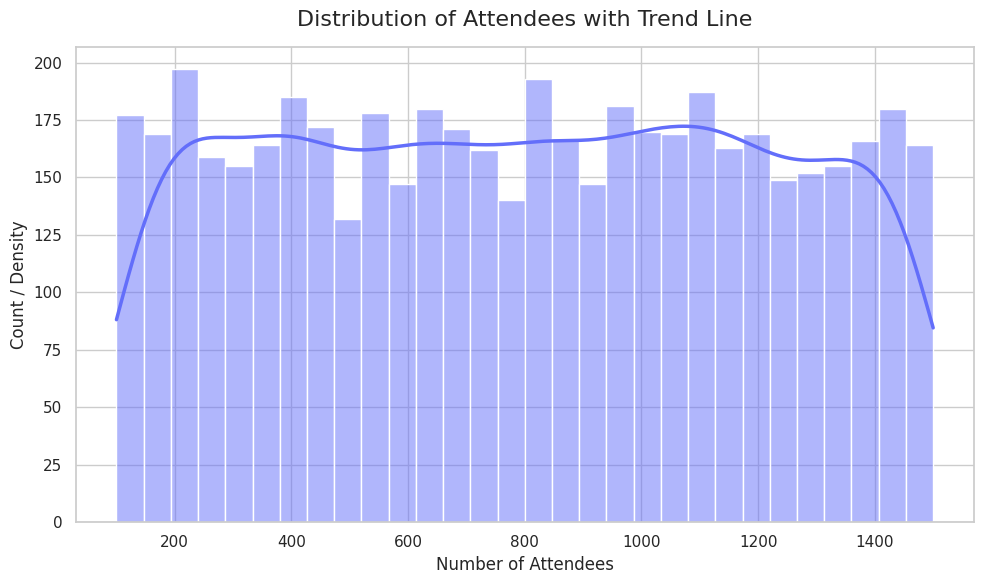

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# Set the aesthetic style
sns.set_theme(style="whitegrid")

plt.figure(figsize=(10, 6))

# Create the histogram with a KDE (Kernel Density Estimate) line overlaid
sns.histplot(
    data=df,
    x="Attendees",
    kde=True,
    bins=30,
    color="#636EFA",
    line_kws={"linewidth": 2.5, "color": "#EF553B"}  # Customize the trend line
)

# Add title and clean labels
plt.title("Distribution of Attendees with Trend Line", fontsize=16, pad=15)
plt.xlabel("Number of Attendees", fontsize=12)
plt.ylabel("Count / Density", fontsize=12)

plt.tight_layout()
plt.show()

In [ ]:
# Creating a status label column for vibrant discrete mapping
df['Success_Status'] = df['Success'].map({1: 'Successful (1)', 0: 'Unsuccessful (0)'})

# Create interactive scatter plot
fig = px.scatter(
    df,
    x="Attendees",
    y="Expenses",
    color="Success_Status",
    color_discrete_map={
        "Successful (1)": "#00CC96",   # Bright emerald green
        "Unsuccessful (0)": "#EF553B"  # Vibrant coral red
    },
    title="Attendees vs. Expenses (Colored by Success Status)",
    labels={
        "Attendees": "Number of Attendees",
        "Expenses": "Expenses ($)",
        "Success_Status": "Event Status"
    },
    hover_data=["Event Type", "Attendees", "Expenses", "Success"],
    template="plotly_white"
)

fig.update_traces(marker=dict(size=8, opacity=0.8, line=dict(width=0.5, color='white')))
fig.update_layout(title_font_size=20, xaxis_title_font_size=14, yaxis_title_font_size=14)
fig.show()

In [ ]:
# Take a clean sample of 150 rows to make the scatter plot beautifully spacious and easy to read
df_sample = df.sample(n=150, random_state=42)

# Create a clean, interactive scatter plot using the sampled data
fig = px.scatter(
    df_sample,
    x="Attendees",
    y="Expenses",
    color="Success_Status",
    color_discrete_map={
        "Successful (1)": "#00CC96",   # Vibrant Green
        "Unsuccessful (0)": "#FF4136"  # Vibrant Red
    },
    title="Attendees vs. Expenses (Spacious Sample of 150 Events)",
    labels={
        "Attendees": "Number of Attendees",
        "Expenses": "Expenses ($)",
        "Success_Status": "Event Status"
    },
    hover_data=["Event Type", "Attendees", "Expenses", "Success"],
    template="plotly_white"
)

# Adjust marker size and transparency for a clean, professional aesthetic
fig.update_traces(
    marker=dict(
        size=10,
        opacity=0.85,
        line=dict(width=1, color='white')
    )
)

fig.update_layout(
    title_font_size=18,
    xaxis_title_font_size=13,
    yaxis_title_font_size=13,
    legend_title_text='Alert / Status'
)

fig.show()

In [ ]:
# Create an interactive categorical scatter plot (Strip Plot) using a spacious sample
fig = px.strip(
    df_sample,
    x="Event Type",
    y="Expenses",
    color="Success_Status",
    color_discrete_map={
        "Successful (1)": "#00CC96",   # Vibrant Green
        "Unsuccessful (0)": "#FF4136"  # Vibrant Red
    },
    title="Expenses Distribution by Event Type (Sample of 150 Events)",
    labels={
        "Event Type": "Category of Event",
        "Expenses": "Expenses ($)",
        "Success_Status": "Event Status"
    },
    hover_data=["Event Type", "Attendees", "Expenses", "Success"],
    template="plotly_white"
)

# Stylize markers
fig.update_traces(
    marker=dict(
        size=9,
        opacity=0.8,
        line=dict(width=0.8, color='white')
    )
)

fig.update_layout(
    title_font_size=18,
    xaxis_title_font_size=13,
    yaxis_title_font_size=13,
    legend_title_text='Alert / Status'
)

fig.show()

In [ ]:
import plotly.express as px

# Create an interactive boxplot to show the distribution of expenses
fig = px.box(
    df,
    x="Event Type",
    y="Expenses",
    color="Success_Status",
    color_discrete_map={
        "Successful (1)": "#00CC96",   # Vibrant Green
        "Unsuccessful (0)": "#FF4136"  # Vibrant Red
    },
    title="Expenses Distribution by Event Type & Success Status",
    labels={
        "Event Type": "Category of Event",
        "Expenses": "Expenses ($)",
        "Success_Status": "Event Status"
    },
    template="plotly_white",
    points="outliers"  # Shows outlier data points clearly
)

# Stylize the layout for a clean, professional aesthetic
fig.update_layout(
    title_font_size=18,
    xaxis_title_font_size=13,
    yaxis_title_font_size=13,
    legend_title_text='Alert / Status'
)

fig.show()